# Gasto público en pensiones y pobreza de las personas mayores

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "gasto-pensiones-pobreza-mayores"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto público en pensiones y pobreza de las personas mayores"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Gasto público en pensiones", "unidad": "% del PIB"}
EJE_Y = {"titulo": "Personas de más de 65 años en pobreza relativa", "unidad": "% de la población de más de 65 años"}
EDAD_Y = "Y_GT65"  # tramo de edad del eje y en la base de distribución de la renta de la OCDE
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes el mismo año.

- **Eje horizontal:** el **gasto público en pensiones** de jubilación y supervivencia en porcentaje del PIB (el mismo indicador que `gasto-pensiones-pib`).
- **Eje vertical:** el porcentaje de las **personas de más de 65 años en pobreza relativa**: las que viven en hogares con una renta disponible, ajustada por el tamaño del hogar, inferior a la mitad de la mediana de su país (el umbral habitual de la OCDE).

**Para qué sirve.** Es el argumento de quienes defienden subir o mantener las pensiones: que el gasto en pensiones protege a las personas mayores de la pobreza. Su pareja es `gasto-pensiones-pobreza-infantil`, con el argumento de quienes sostienen que ese gasto deja menos recursos para otras prestaciones y para las generaciones jóvenes. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El gasto en porcentaje del PIB depende también de cuántas personas mayores hay en cada país, no solo de cuánto cobra cada una.
- La pobreza de los mayores depende de otras rentas: planes de pensiones de empresa e individuales (muy extendidos en países como los Países Bajos, Estados Unidos o Canadá), ahorros o rentas del trabajo. La renta no incluye el valor de la vivienda en propiedad, que tienen muchas personas mayores.
- El umbral es relativo a la mediana de cada país: no compara niveles de vida entre países.
- Cada país usa su propia encuesta de ingresos, armonizada por la OCDE.

## 2. Descarga

- **Eje x:** OCDE, base de gasto social (SOCX, `OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0`), gasto público (`ES10`) en prestaciones en dinero (`C`) de vejez y supervivencia (`TP01`), en % del PIB, para los países de la OCDE y la media `OECD`.
- **Eje y:** OCDE, base de distribución de la renta (IDD, `OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0`), tasa de pobreza con la renta disponible (`PR_INC_DISP`), umbral del 50 % de la mediana (`PL_50`), definición de renta vigente (`METH2012`, `D_CUR`), población de más de 65 años (`Y_GT65`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta

AREAS = {c: c for c in [*PAISES, "OECD"]}  # países del universo y la media, con su código como clave de serie
HOY = date.today().isoformat()

# SOCX: REF_AREA.FREQ.MEASURE.UNIT_MEASURE.EXPEND_SOURCE.SPENDING_TYPE.PROGRAMME_TYPE.PRICE_BASE
DATAFLOW_SOCX = "OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0"
CLAVE_SOCX = "{AREA}.A.SOCX.PT_B1GQ.ES10.C.TP01._Z"
# IDD: REF_AREA.FREQ.MEASURE.STATISTICAL_OPERATION.UNIT_MEASURE.AGE.METHODOLOGY.DEFINITION.POVERTY_LINE
DATAFLOW_IDD = "OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0"
CLAVE_IDD = f"{{AREA}}.A.PR_INC_DISP._Z.PT_POP.{EDAD_Y}.METH2012.D_CUR.PL_50"

x, _ = oecd.get(DATAFLOW_SOCX, CLAVE_SOCX, areas=AREAS, desde=DESDE)
y, _ = oecd.get(DATAFLOW_IDD, CLAVE_IDD, areas=AREAS, desde=DESDE)
print("Con gasto en pensiones:", x["serie"].nunique(), "· con tasa de pobreza:", y["serie"].nunique())
print("Media OCDE en el eje y:", "OECD" in set(y["serie"]))

Con gasto en pensiones: 39 · con tasa de pobreza: 37
Media OCDE en el eje y: False


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE.
2. **Media de la OCDE:** SOCX publica la media de la OCDE, pero la IDD no; el escritor solo la añade como punto si tiene dato en los dos ejes el mismo año.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

### Notas

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


_, FLUJO_SOCX, VER_SOCX = DATAFLOW_SOCX.split(",")
_, FLUJO_IDD, VER_IDD = DATAFLOW_IDD.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_SOCX} (SOCX, versión {VER_SOCX}): TP01, ES10, C, PT_B1GQ", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_IDD} (IDD, versión {VER_IDD}): PR_INC_DISP, {EDAD_Y}, METH2012, D_CUR, PL_50", oecd.URL_EXPLORER, HOY),
]
NOTAS = [
    "Gasto en pensiones: OCDE, base de gasto social (SOCX), gasto público en prestaciones en dinero de vejez y "
    "supervivencia (TP01, ES10, C), en % del PIB; incluye las pensiones de todas las administraciones públicas y no "
    "las de incapacidad.",
    "Pobreza de las personas mayores: OCDE, base de distribución de la renta (IDD), porcentaje de las personas de más "
    "de 65 años en hogares con una renta disponible equivalente inferior al 50 % de la mediana nacional (definición "
    "de renta vigente desde 2012). La renta no incluye el valor de la vivienda en propiedad.",
    "La IDD no publica la media de la OCDE: no hay punto de la media.",
    "El gasto en % del PIB depende también de cuántas personas mayores hay en cada país, y la pobreza de los mayores, "
    "de otras rentas, como los planes de pensiones de empresa e individuales o el ahorro.",
]

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

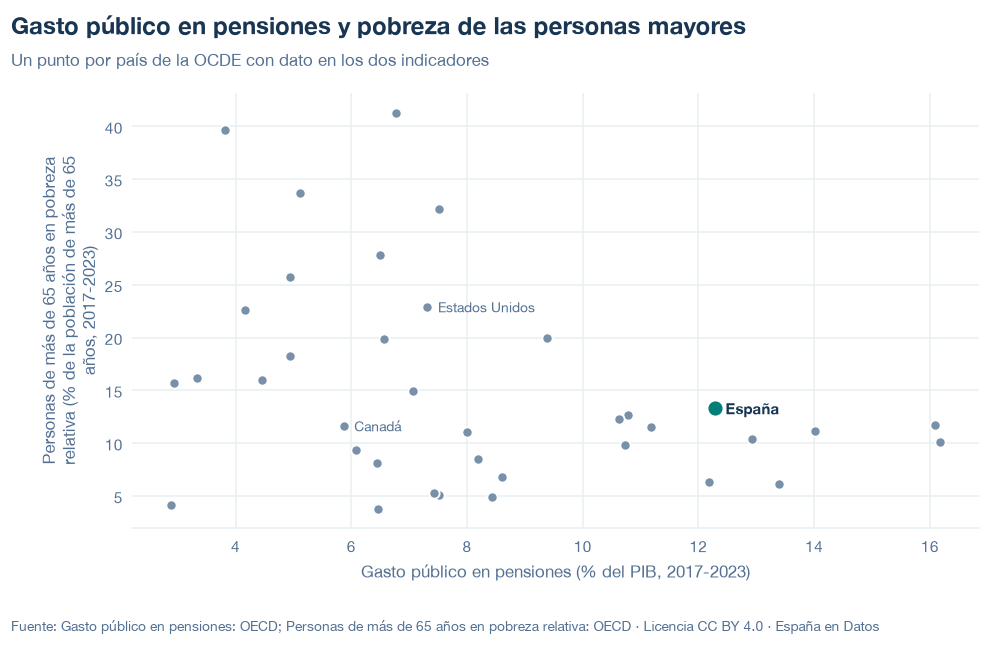

codigo  anio      x         y
   AUS  2020  4.160 22.600000
   AUT  2021 14.017 11.185528
   BEL  2021 10.724  9.816511
   CAN  2022  5.867 11.600000
   CHE  2021  6.558 19.840289
   CHL  2022  3.328 16.156845
   CRI  2022  4.939 25.772330
   CZE  2021  8.191  8.542503
   DEU  2021 10.791 12.620001
   DNK  2021  7.513  5.120000
   ESP  2021 12.282 13.284954
   EST  2021  6.778 41.303295
   FIN  2021 12.176  6.317520
   FRA  2022 13.396  6.100000
   GBR  2022  7.072 14.922366
   GRC  2021 16.183 10.082848
   HUN  2017  8.431  4.890145
   IRL  2021  2.933 15.695009
   ISL  2019  2.876  4.180948
   ISR  2023  4.464 16.003883
   ITA  2021 16.089 11.715961
   JPN  2021  9.379 20.000000
   KOR  2022  3.810 39.700001
   LTU  2021  6.498 27.784237
   LUX  2021  8.611  6.831910
   LVA  2021  7.519 32.163322
   MEX  2022  4.943 18.292951
   NLD  2021  6.444  8.100000
   NOR  2021  6.463  3.800000
   NZL  2022  5.121 33.700000
   POL  2021 11.187 11.489645
   PRT  2021 12.919 10.345426
   SVK  20

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-pensiones-pobreza-mayores.json y data/gasto-pensiones-pobreza-mayores.csv


## 6. Fuentes, notas y licencia

- OCDE, SOCX: `OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0` (`TP01`, `ES10`, `C`, `PT_B1GQ`).
- OCDE, IDD: `OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0` (`PR_INC_DISP`, `Y_GT65`, `METH2012`, `D_CUR`, `PL_50`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.